# Evidence Intelligence Pipeline — MASH Competitive Landscape

**Goal.** Give a European biotech preparing a Series C board presentation a fact-based view of the
MASH (metabolic dysfunction-associated steatohepatitis, formerly NASH) treatment landscape: who the key
players are, which mechanisms dominate, and where white space exists for a new entrant.

**What this notebook does**

| Step | Module | Output |
|---|---|---|
| 1. Literature mining (PubMed, 2020–2025) | `src/pubmed.py` | `data/raw/pubmed_data.json` |
| 2. Trial landscape (ClinicalTrials.gov, Phase 2/3) | `src/trials.py` | `data/raw/trials_data.json` |
| 3a. LLM extraction, one record per source | `src/extraction.py` | `data/processed/extraction_pass1.json` |
| 3b. LLM normalisation: canonical drug + mechanism class | `src/normalize.py` | `data/processed/drug_map.csv` |
| 3c. Landscape assembly | `src/landscape.py` | `outputs/landscape_data.csv`, `data/processed/compounds.csv` |
| 3d. Quality assurance of the LLM output | `src/validate.py` | tables below |
| 4. Charts and 5-slide deck | `src/analysis.py`, `src/deck.py` | `outputs/figures/`, `outputs/findings_deck.pptx` |

**Design principles**

1. *Structured data is never routed through the LLM.* Phase, sponsor, status and dates come straight
   from the ClinicalTrials.gov API; the LLM only reads free text.
2. *Two LLM passes.* Pass 1 is strictly source-grounded (one call per record). Pass 2 works per unique
   compound and may use pharmacology knowledge, which is flagged in the output (`moa_source`).
3. *Fixed vocabularies.* Categorical fields are enums in the output schema, so no free-text spelling
   variants need cleaning later.
4. *Reproducible and cheap to re-run.* Every API response is cached on disk; re-running the notebook makes
   no new API calls unless inputs, prompt or model change. A hard spending cap guards the LLM step.

**How to run.** `pip install -r requirements.txt`, put `OPENAI_API_KEY=...` in `.env`, then *Run All*.

In [ ]:
import json
import pandas as pd
from IPython.display import Image, display

from src import config, pubmed, trials, extraction, normalize, landscape, validate, analysis, deck

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

REFRESH_SOURCES = False   # True = query PubMed / ClinicalTrials.gov again instead of using saved raw files
print("LLM model:", config.LLM_MODEL, "| reasoning effort:", config.LLM_REASONING_EFFORT,
      "| budget cap: $", config.LLM_BUDGET_USD)

## 1. Literature mining — PubMed

**Query design.** Disease terms (MeSH *Non-alcoholic Fatty Liver Disease*, MASH, NASH, steatohepatitis)
× treatment terms × clinical publication types, restricted to human studies in English with an abstract.

**Sampling.** Relevance-sorted results cluster in recent years, so the search runs **per publication year**
(2020–2025) and per evidence stratum: 17 primary clinical trials + 8 meta-analyses / systematic reviews
per year (≈150 records). Primary trials carry more weight for a competitive landscape.

In [2]:
print(pubmed.build_query(2024, "primary_trial"))

("Non-alcoholic Fatty Liver Disease"[MeSH] OR MASH[tiab] OR NASH[tiab] OR "steatohepatitis"[tiab] OR "metabolic dysfunction-associated steatohepatitis"[tiab]) AND (drug therapy[sh] OR treatment[tiab] OR therapy[tiab] OR efficacy[tiab] OR agonist[tiab] OR inhibitor[tiab]) AND (Clinical Trial[pt] OR Randomized Controlled Trial[pt] OR Clinical Trial, Phase II[pt] OR Clinical Trial, Phase III[pt]) NOT (Meta-Analysis[pt] OR Systematic Review[pt]) AND humans[MeSH] AND english[la] AND hasabstract AND ("2024/01/01"[dp] : "2024/12/31"[dp])


In [3]:
pubmed_raw = pubmed.collect(refresh=REFRESH_SOURCES)
pubmed_df = pubmed.to_dataframe(pubmed_raw)

print(f"Raw records: {len(pubmed_raw)} | with abstract (kept): {len(pubmed_df)}")
display(pubmed_df.groupby(["publication_year", "stratum"]).size().unstack())
display(pubmed_df["study_design"].value_counts().to_frame("articles"))

Loaded 150 cached PubMed records
Raw records: 150 | with abstract (kept): 140


stratum,meta_analysis,primary_trial
publication_year,,
2020,8,17
2021,6,15
2022,8,15
2023,8,16
2024,7,16
2025,8,16


,articles
study_design,
Randomized controlled trial,57
Meta-analysis / systematic review,45
Phase 2 trial,22
Other clinical trial,8
Phase 3 trial,8


In [4]:
pubmed_df[["pmid", "publication_year", "study_design", "journal", "title"]].head(8)

,pmid,publication_year,study_design,journal,title
0,33185364,2020,Phase 2 trial,The New England journal of medicine,A Placebo-Controlled Trial of Subcutaneous Semaglutide in Nonalcoholic Steatohepatitis.
1,32033759,2020,Other clinical trial,Gastroenterology clinics of North America,Recruitment and Retention of Patients for Nonalcoholic Steatohepatitis Clinical Trials.
2,32291277,2020,Phase 2 trial,Diabetes care,Effects of Novel Dual GIP and GLP-1 Receptor Agonist Tirzepatide on Biomarkers of Nonalcoholic Steatohepatitis in Pa...
3,32147362,2020,Phase 3 trial,Journal of hepatology,Selonsertib for patients with bridging fibrosis or compensated cirrhosis due to NASH: Results from randomized phase ...
4,33060043,2020,Phase 3 trial,Digestive and liver disease : official journal of the Italian Society of Gastroenterology and the Italian Associatio...,Antioxidant activity of Hydroxytyrosol and Vitamin E reduces systemic inflammation in children with paediatric NAFLD.
5,32147075,2020,Randomized controlled trial,Complementary therapies in medicine,Effects of curcuminoids on inflammatory status in patients with non-alcoholic fatty liver disease: A randomized cont...
6,33358648,2020,Randomized controlled trial,JACC. Cardiovascular interventions,Suture- or Plug-Based Large-Bore Arteriotomy Closure: A Pilot Randomized Controlled Trial.
7,32885600,2020,Randomized controlled trial,Clinical obesity,Bariatric surgery during the evolution of fatty liver-A randomized clinical trial comparing gastric bypass and sleev...


## 2. Trial landscape — ClinicalTrials.gov

Interventional **Phase 2 and Phase 3** studies (including Phase 1/2 and 2/3) for MASH/NASH, all statuses.
Each record is flattened to one row. Registry fields are used as-is:

* `phase`, `highest_phase` — from `designModule.phases`
* `status_group` — Completed / Ongoing / Stopped early / Unknown
* `sponsor_type` — Industry / Academic or hospital / Government
* `disease_scope` — core MASH/NASH vs broader MASLD/NAFLD
* `results_summary` — for trials with posted results, a compact text of primary-outcome results and
  serious adverse events, which lets the LLM extract efficacy and safety for registry records.

In [5]:
trials_raw = trials.collect(refresh=REFRESH_SOURCES)
trials_df = trials.to_dataframe(trials_raw)

print(f"Trials: {len(trials_df)} | with posted results: {trials_df['has_results'].sum()}")
for col in ["phase", "status_group", "sponsor_type", "disease_scope"]:
    display(trials_df[col].value_counts().to_frame("trials"))

Loaded 498 cached trial records
Trials: 498 | with posted results: 182


,trials
phase,
Phase 2,339
Phase 3,88
Phase 1/2,48
Phase 2/3,23


,trials
status_group,
Completed,272
Ongoing,107
Stopped early,77
Unknown,42


,trials
sponsor_type,
Industry,275
Academic / hospital,195
Government,28


,trials
disease_scope,
MASH/NASH,326
MASLD/NAFLD (broader),157
Other,15


In [6]:
example = trials_df[trials_df["results_summary"].notna()].iloc[0]
print(example["nct_id"], "-", example["title"])
print(example["results_summary"][:800])

NCT02681055 - Open-Label Study To Evaluate MN-001 on HDL & Triglyceride in NASH & NAFLD Subjects
PRIMARY OUTCOME: Mean Change From Baseline at 12 Weeks of MN-001 Treatment on Cholesterol Efflux Capacity [percentage of cholesterol, Baseline, 12 weeks]
  Open Label Arm: -0.013
PRIMARY OUTCOME: Mean Change From Baseline to Week 8 on Triglyceride Levels After 8 Weeks MN-001 Treatment [mg/dL, 8 weeks]
  Open Label Arm: -21.67
SERIOUS AEs - Open Label Arm: 0/19 affected; deaths 0


## 3a. LLM extraction — pass 1 (source-grounded)

One call per record. The schema (`RecordExtraction`) asks for:

| Field | Type |
|---|---|
| `relevant` | bool — is this about treating MASH/MASLD? (drops off-topic keyword hits) |
| `drugs` | list of {name, role}; role ∈ investigational / active comparator / background therapy / non-drug |
| `mechanism_of_action` | text, only if stated in the source |
| `primary_endpoint`, `efficacy_outcome`, `safety_signal` | short quantitative text; results only, never plans |
| `efficacy_direction` | positive / negative / mixed / not reported — judged on the primary endpoint |
| `evidence_type`, `study_phase` | enums |

`trial_phase`, `sponsor_type`, `data_source` and `source_id` are attached afterwards from the metadata.

In [7]:
print(extraction.SYSTEM_PROMPT)
items = extraction.build_inputs(pubmed_df, trials_df)
print(f"\nRecords to extract: {len(items)} "
      f"(already cached: {extraction.cached_count(items)}) | prompt version {extraction.PROMPT_VERSION}")

You are a biomedical evidence analyst building a competitive
intelligence dataset on MASH (formerly NASH) treatments.

Extract the requested fields from ONE source record (a PubMed abstract or a
ClinicalTrials.gov registry entry).

Rules:
- Use only information stated in the source. Never add outside knowledge.
- drugs: list every pharmacological intervention and tag its role. Placebo is
  not a drug. Lifestyle, diet, surgery, devices -> 'non-drug intervention'.
- For a meta-analysis, the investigational drugs are the ones being pooled.
- efficacy_outcome and safety_signal: only actual results (numbers, p-values,
  event rates). A planned outcome is NOT a result -> null.
- efficacy_direction, judged on the PRIMARY endpoint:
    positive = met with statistical significance (e.g. p<0.05 vs control);
    negative = not met / no significant difference (e.g. p>=0.05);
    mixed = met for some doses or co-primary endpoints but not others;
    not reported = no results in the source.
- For re

In [8]:
print(items[0]["text"][:1200])

SOURCE: PubMed (PMID 33185364)
TITLE: A Placebo-Controlled Trial of Subcutaneous Semaglutide in Nonalcoholic Steatohepatitis.
JOURNAL: The New England journal of medicine (2020)
PUBLICATION TYPES: Clinical Trial, Phase II, Journal Article, Multicenter Study, Randomized Controlled Trial, Research Support, Non-U.S. Gov't

ABSTRACT:
BACKGROUND: Nonalcoholic steatohepatitis (NASH) is a common disease that is associated with increased morbidity and mortality, but treatment options are limited. The efficacy and safety of the glucagon-like peptide-1 receptor agonist semaglutide in patients with NASH is not known. METHODS: We conducted a 72-week, double-blind phase 2 trial involving patients with biopsy-confirmed NASH and liver fibrosis of stage F1, F2, or F3. Patients were randomly assigned, in a 3:3:3:1:1:1 ratio, to receive once-daily subcutaneous semaglutide at a dose of 0.1, 0.2, or 0.4 mg or corresponding placebo. The primary end point was resolution of NASH with no worsening of fibrosis

In [9]:
extraction_df, extraction_errors = extraction.extract_all(items, workers=8)
extraction_df.to_json(config.PROCESSED_DIR / "extraction_pass1.json", orient="records",
                      force_ascii=False, indent=1)
print("Errors:", extraction_errors)

LLM pass 1:   0%|          | 0/623 [00:00<?, ?it/s]

LLM pass 1: 100%|██████████| 623/623 [00:00<00:00, 17118.15it/s]

Extracted 623 records, 0 errors (model gpt-6-luna, prompt df47e07a)
New API calls this run: 0, spend $0.0000 of $0.60 budget
Errors: []


In [10]:
fields = ["drugs", "mechanism_of_action", "primary_endpoint", "efficacy_outcome", "safety_signal"]
filled = lambda s: s.apply(lambda v: bool(v) if isinstance(v, (list, str)) else pd.notna(v))
rel = extraction_df[extraction_df["relevant"]]
display(pd.DataFrame({f: rel.groupby("data_source")[f].apply(lambda s: f"{filled(s).mean():.0%}")
                      for f in fields}))
display(extraction_df["relevant"].value_counts().to_frame("records"))
display(pd.crosstab(extraction_df["data_source"], extraction_df["efficacy_direction"]))

,drugs,mechanism_of_action,primary_endpoint,efficacy_outcome,safety_signal
data_source,,,,,
ClinicalTrials.gov,100%,10%,99%,31%,37%
PubMed,99%,53%,57%,85%,41%


,records
relevant,
True,585
False,38


efficacy_direction,mixed,negative,not reported,positive
data_source,,,,
ClinicalTrials.gov,16,57,381,29
PubMed,11,17,51,61


## 3b. LLM normalisation — pass 2 (compound level)

Drug names are first cleaned deterministically (case, doses, salts). The **unique** names are then sent in
batches of 60 to the LLM, which returns a canonical INN name, one of 26 mechanism classes and whether the
compound is a *novel MASH agent* (as opposed to a vitamin, supplement or long-generic repurposed drug).
A short manual override table fixes abbreviations used inside trial arms.

In [11]:
mentions = landscape.explode_drugs(extraction_df)
print(f"Investigational drug mentions: {len(mentions)} | unique cleaned names: {mentions['clean_name'].nunique()}")

drug_map = normalize.normalize_drugs(mentions["clean_name"].tolist())
drug_map.to_csv(config.PROCESSED_DIR / "drug_map.csv", index=False)

# examples of names merged into one compound
merged = drug_map.groupby("canonical_name")["clean_name"].agg(list)
display(merged[merged.str.len() > 2].head(10).to_frame("raw names merged"))

Investigational drug mentions: 680 | unique cleaned names: 429
Normalised 429 names -> 331 compounds; spend so far $0.0000


,raw names merged
canonical_name,
acetylcysteine,"[n acetyl cysteine, n-acetyl cysteine, n-acetyl cysteine (nac), n-acetylcysteine]"
aldafermin,"[aldafermin, aldafermin (ngm282), ngm282, ngm282 (aldafermin)]"
aramchol,"[aramchol, aramchol free acid, stearoyl-coa desaturase-1]"
cilofexor,"[cilo, cilofexor, gs-9674]"
cotadutide,"[cotadutide, medi0382, sar425899]"
curcumin,"[curcumin, curcumin meriva, curcuvail® (curcuma longa extract containing 35% curcuminoids), phytosomal curcumin]"
efruxifermin,"[efruxifermin, efx, mk-3655]"
emricasan,"[emricasan, emricasan (idn-6556-12), idn-6556]"
glp-1 receptor agonists,"[glp-1 agonists, glp-1 ras, glp-1ras]"


## 3c. Landscape dataset

`landscape_data.csv` has **one row per investigational compound × source record** with the fields the brief
asks for (drug name, mechanism of action, trial phase, primary endpoint, efficacy outcome, safety signal,
sponsor type, data source) plus mechanism class, `moa_source`, efficacy direction, status and IDs.

`compounds.csv` aggregates to one row per compound for the competitive map.

In [12]:
landscape_df = landscape.build_landscape(extraction_df, drug_map, pubmed_df, trials_df)
compounds_df = landscape.build_compounds(landscape_df)

display(landscape_df["moa_source"].value_counts().to_frame("rows"))
landscape_df.head(5)

landscape_data.csv: 674 rows, 331 compounds


compounds.csv: 331 compounds, 103 novel MASH agents


,rows
moa_source,
model knowledge,550
source-reported,124


,drug_name,drug_name_raw,moa_class,mechanism_of_action,moa_source,novel_mash_agent,trial_phase,primary_endpoint,efficacy_outcome,efficacy_direction,safety_signal,sponsor_name,sponsor_type,status_group,evidence_type,disease_scope,year,enrollment,data_source,source_id
0,13c-methacetin,13C-Methacetin,Other,13C-labelled diagnostic probe,model knowledge,False,Phase 3,Compare mean and standard deviation of Breath ID system results among three NAFLD/NASH patient groups using chi-squa...,NaN,not reported,NaN,Virginia Commonwealth University,Academic / hospital,Completed,registry record,MASLD/NAFLD (broader),2005.0,120.0,ClinicalTrials.gov,NCT00244569
1,68ga-fapi-46,68Ga-FAPI-46,Other,Radiolabelled fibroblast activation protein imaging tracer,model knowledge,False,Phase 2,Capture intensity measurement at 1 year.,NaN,not reported,NaN,"Central Hospital, Nancy, France",Academic / hospital,Ongoing,registry record,MASH/NASH,2024.0,72.0,ClinicalTrials.gov,NCT06160271
2,CM-101,CM-101,Other anti-fibrotic / anti-inflammatory,Monoclonal antibody blocking CCL24.,source-reported,True,Phase 2,Treatment-emergent adverse events (TEAEs) during the 14-week treatment period.,NaN,not reported,NaN,ChemomAb Ltd.,Industry,Completed,registry record,MASH/NASH,2021.0,23.0,ClinicalTrials.gov,NCT05824156
3,CRV431,CRV431,Other anti-fibrotic / anti-inflammatory,Cyclophilin inhibitor,model knowledge,True,Phase 2,"Safety and tolerability events through study day 42, plus CRV431 Tmax, Cmax, and AUC0-last on days 1 and 28.",NaN,not reported,"Treatment-emergent AE counts were reported by dose group, but the listed counts are not labeled by event category. N...","Hepion Pharmaceuticals, Inc.",Industry,Completed,registry record,MASH/NASH,2020.0,47.0,ClinicalTrials.gov,NCT04480710
4,CS060380,CS060380,Unknown,Mechanism not established,model knowledge,False,Phase 2,MRI-PDFF at Day 85 (D85).,NaN,not reported,NaN,"Cascade Pharmaceuticals, Inc",Academic / hospital,Ongoing,registry record,MASH/NASH,2025.0,120.0,ClinicalTrials.gov,NCT07198386


In [13]:
compounds_df[compounds_df["novel_mash_agent"] == True].head(15)[
    ["drug_name", "moa_class", "highest_phase", "n_trials", "n_publications",
     "n_ongoing_industry_trials", "lead_sponsor"]]

,drug_name,moa_class,highest_phase,n_trials,n_publications,n_ongoing_industry_trials,lead_sponsor
282,semaglutide,GLP-1 receptor agonist,Phase 3,12,12,1,Novo Nordisk A/S
279,saroglitazar,PPAR agonist,Phase 3,8,1,0,Zydus Therapeutics Inc.
104,efruxifermin,FGF21 analogue,Phase 3,7,6,3,"Akero Therapeutics, Inc"
226,obeticholic acid,FXR agonist,Phase 3,7,3,0,Intercept Pharmaceuticals
268,resmetirom,THR-beta agonist,Phase 3,7,4,5,"Madrigal Pharmaceuticals, Inc."
101,efimosfermin alfa,FGF21 analogue,Phase 3,6,0,5,GlaxoSmithKline
281,selonsertib,ASK1 / apoptosis inhibitor,Phase 3,6,1,0,Gilead Sciences
65,cenicriviroc,CCR2/CCR5 antagonist,Phase 3,5,0,0,"Tobira Therapeutics, Inc."
298,survodutide,GLP-1/glucagon dual agonist,Phase 3,5,4,3,Boehringer Ingelheim
26,aramchol,Lipogenesis inhibitor (ACC/FASN/SCD1/DGAT2/KHK),Phase 3,4,1,0,"Galmed Research and Development, Ltd."


## 3d. Quality assurance of the LLM output

A cheaper model (`gpt-6-luna`) was chosen for cost. Before using its output we check it, without further
API calls, in two ways:

1. **Automated consistency checks** against information known independently of the LLM.
2. **Manual audit** of a random sample of 13 records (seed 7), each compared field-by-field with the source
   text. The verdicts are recorded in `src/validate.py`.

In [14]:
qa = validate.automated_checks(extraction_df, pubmed_df, trials_df)
display(qa)
audit = validate.manual_audit_summary()
display(audit[audit["n_errors"] > 0])
manual_accuracy = 1 - audit["n_errors"].sum() / (len(audit) * validate.FIELDS_PER_RECORD)

,check,result,base
0,Trial phase matches registry,100%,483 trials
1,Evidence type matches PubMed publication type,95%,132 articles
2,Investigational drug captured when registry lists one,99.3%,429 trials
3,Efficacy invented for trials without posted results,0,304 trials
4,Efficacy direction consistent with reported p-values,94%,85 trials


Manual audit: 13 records, 65 fields, 4 errors -> field accuracy 94%


,source_id,data_source,n_errors,errors
1,40480879,PubMed,1,efficacy_direction: significant result labelled 'not reported'
6,32147075,PubMed,1,drugs: piperine (absorption enhancer) tagged investigational
8,NCT03823703,ClinicalTrials.gov,1,evidence_type: registry entry labelled RCT (now set deterministically)
10,NCT06104319,ClinicalTrials.gov,1,efficacy_direction: 'positive' without a comparator (debatable)


## 4. Analysis, charts and findings deck

The trial analysis uses **core MASH/NASH trials** that the LLM confirmed as relevant. Mechanism breakdowns
count novel agents only, so vitamins and supplements do not distort the competitive picture. On the
competitive map a programme is *active* if it has at least one ongoing **industry-sponsored** trial; an
ongoing academic study alone does not signal commercial development.

In [15]:
core = analysis.core_trials(trials_df, extraction_df)
print("Core MASH/NASH trials:", len(core))

figs = {**analysis.evidence_charts(pubmed_df, landscape_df), **analysis.trial_charts(core, landscape_df)}
map_path, map_table = analysis.competitive_map(compounds_df)
momentum_path, momentum_table = analysis.momentum_chart(core, landscape_df)
display(momentum_table[["Ongoing", "Past", "share_ongoing"]].round(2))

Core MASH/NASH trials: 320


status_group,Ongoing,Past,share_ongoing
moa_class,,,
ASK1 / apoptosis inhibitor,0,11,0.00
Lipogenesis inhibitor (ACC/FASN/SCD1/DGAT2/KHK),0,16,0.00
Other anti-fibrotic / anti-inflammatory,0,18,0.00
FXR agonist,1,23,0.04
PPAR agonist,2,13,0.13
GLP-1/glucagon dual agonist,4,10,0.29
THR-beta agonist,4,6,0.40
GLP-1 receptor agonist,4,5,0.44
FGF21 analogue,10,12,0.45


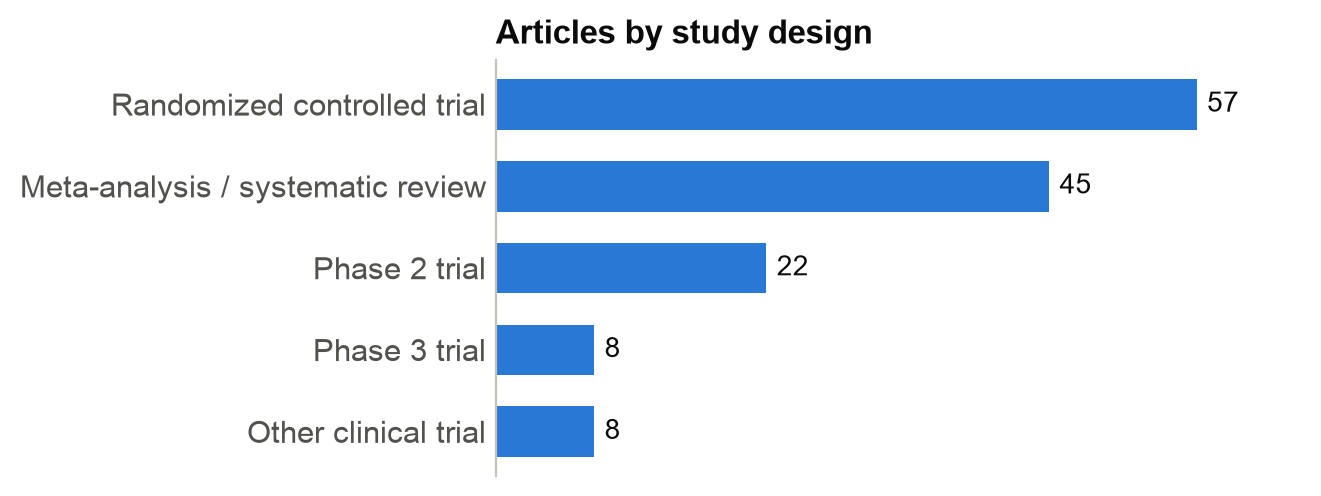

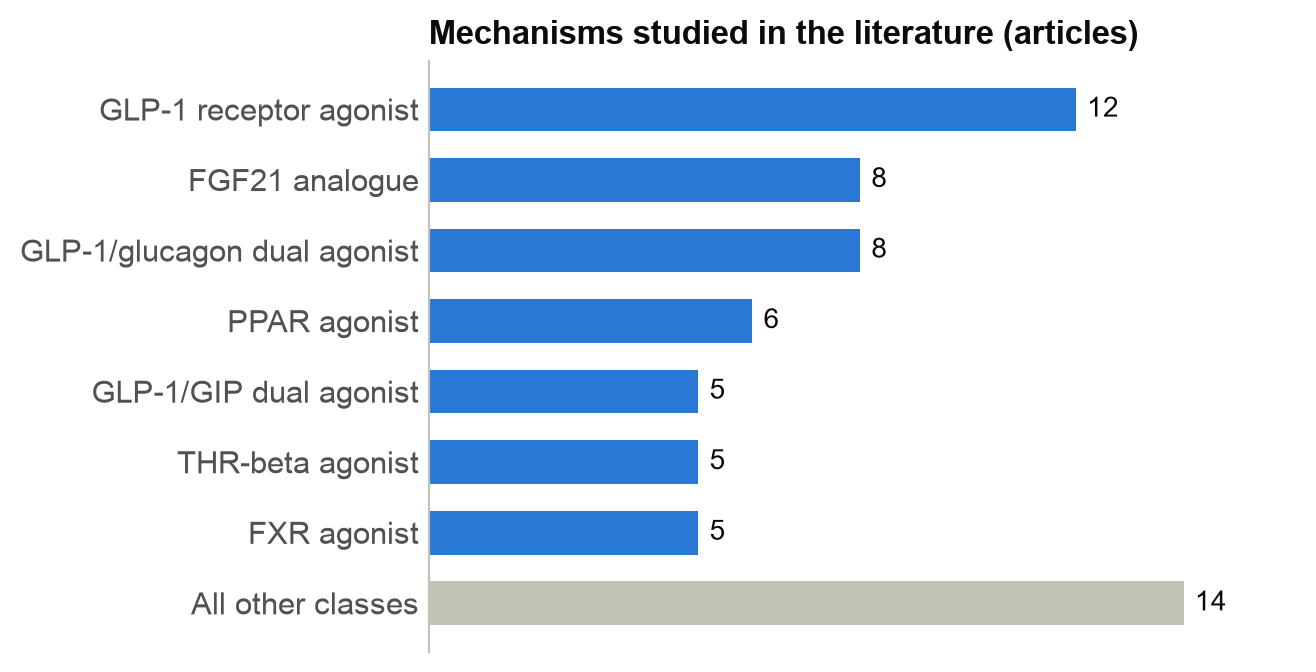

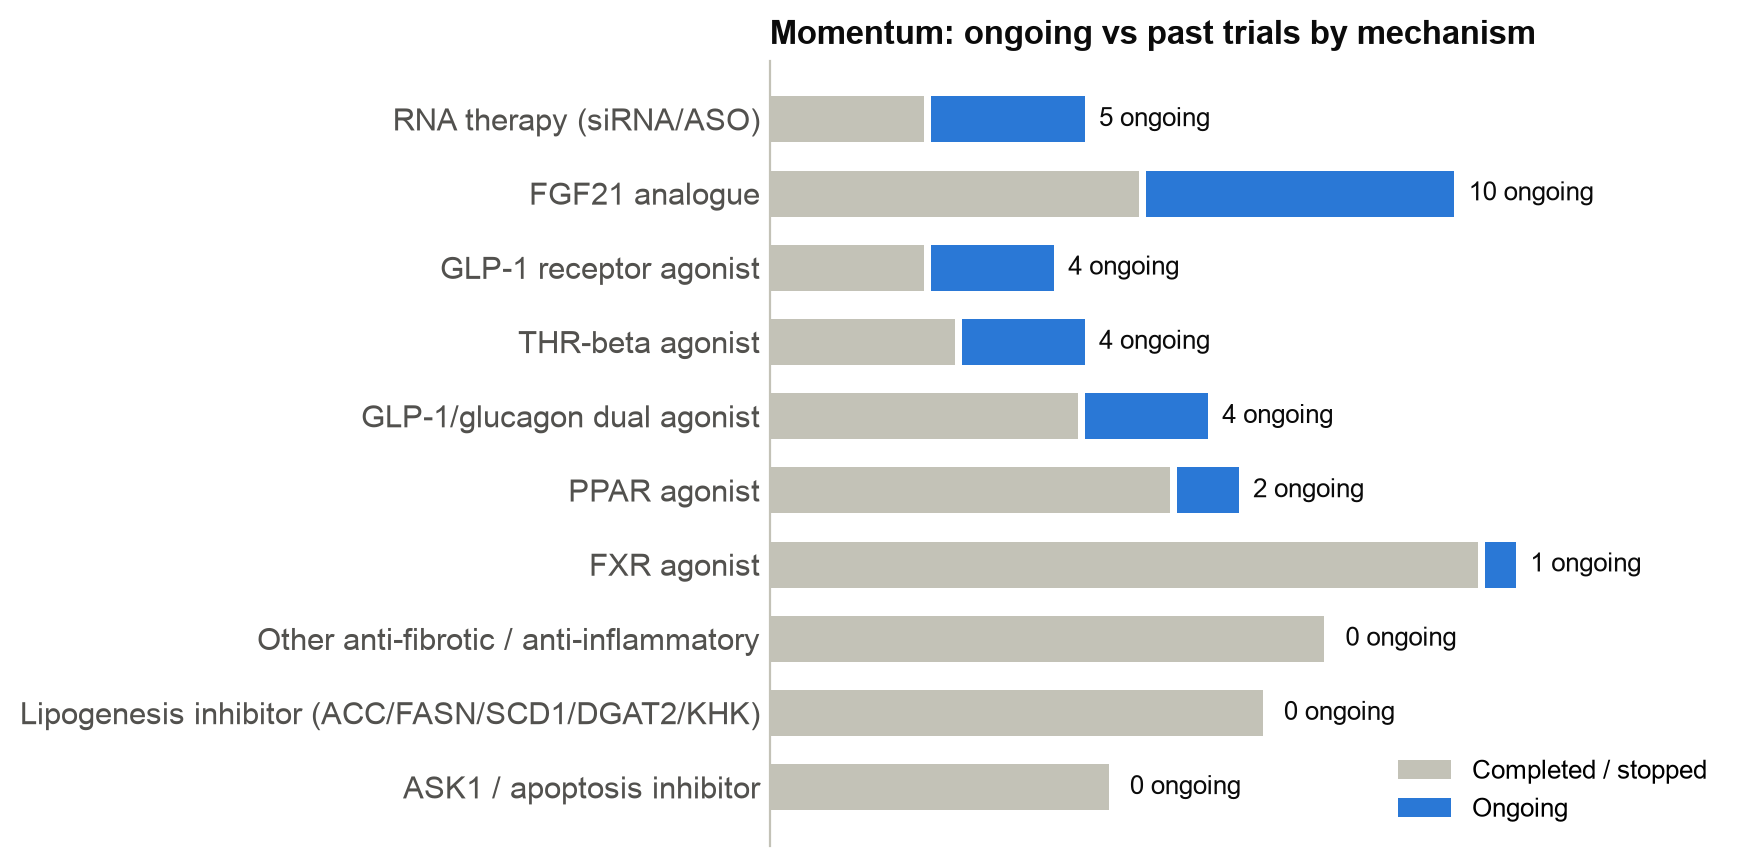

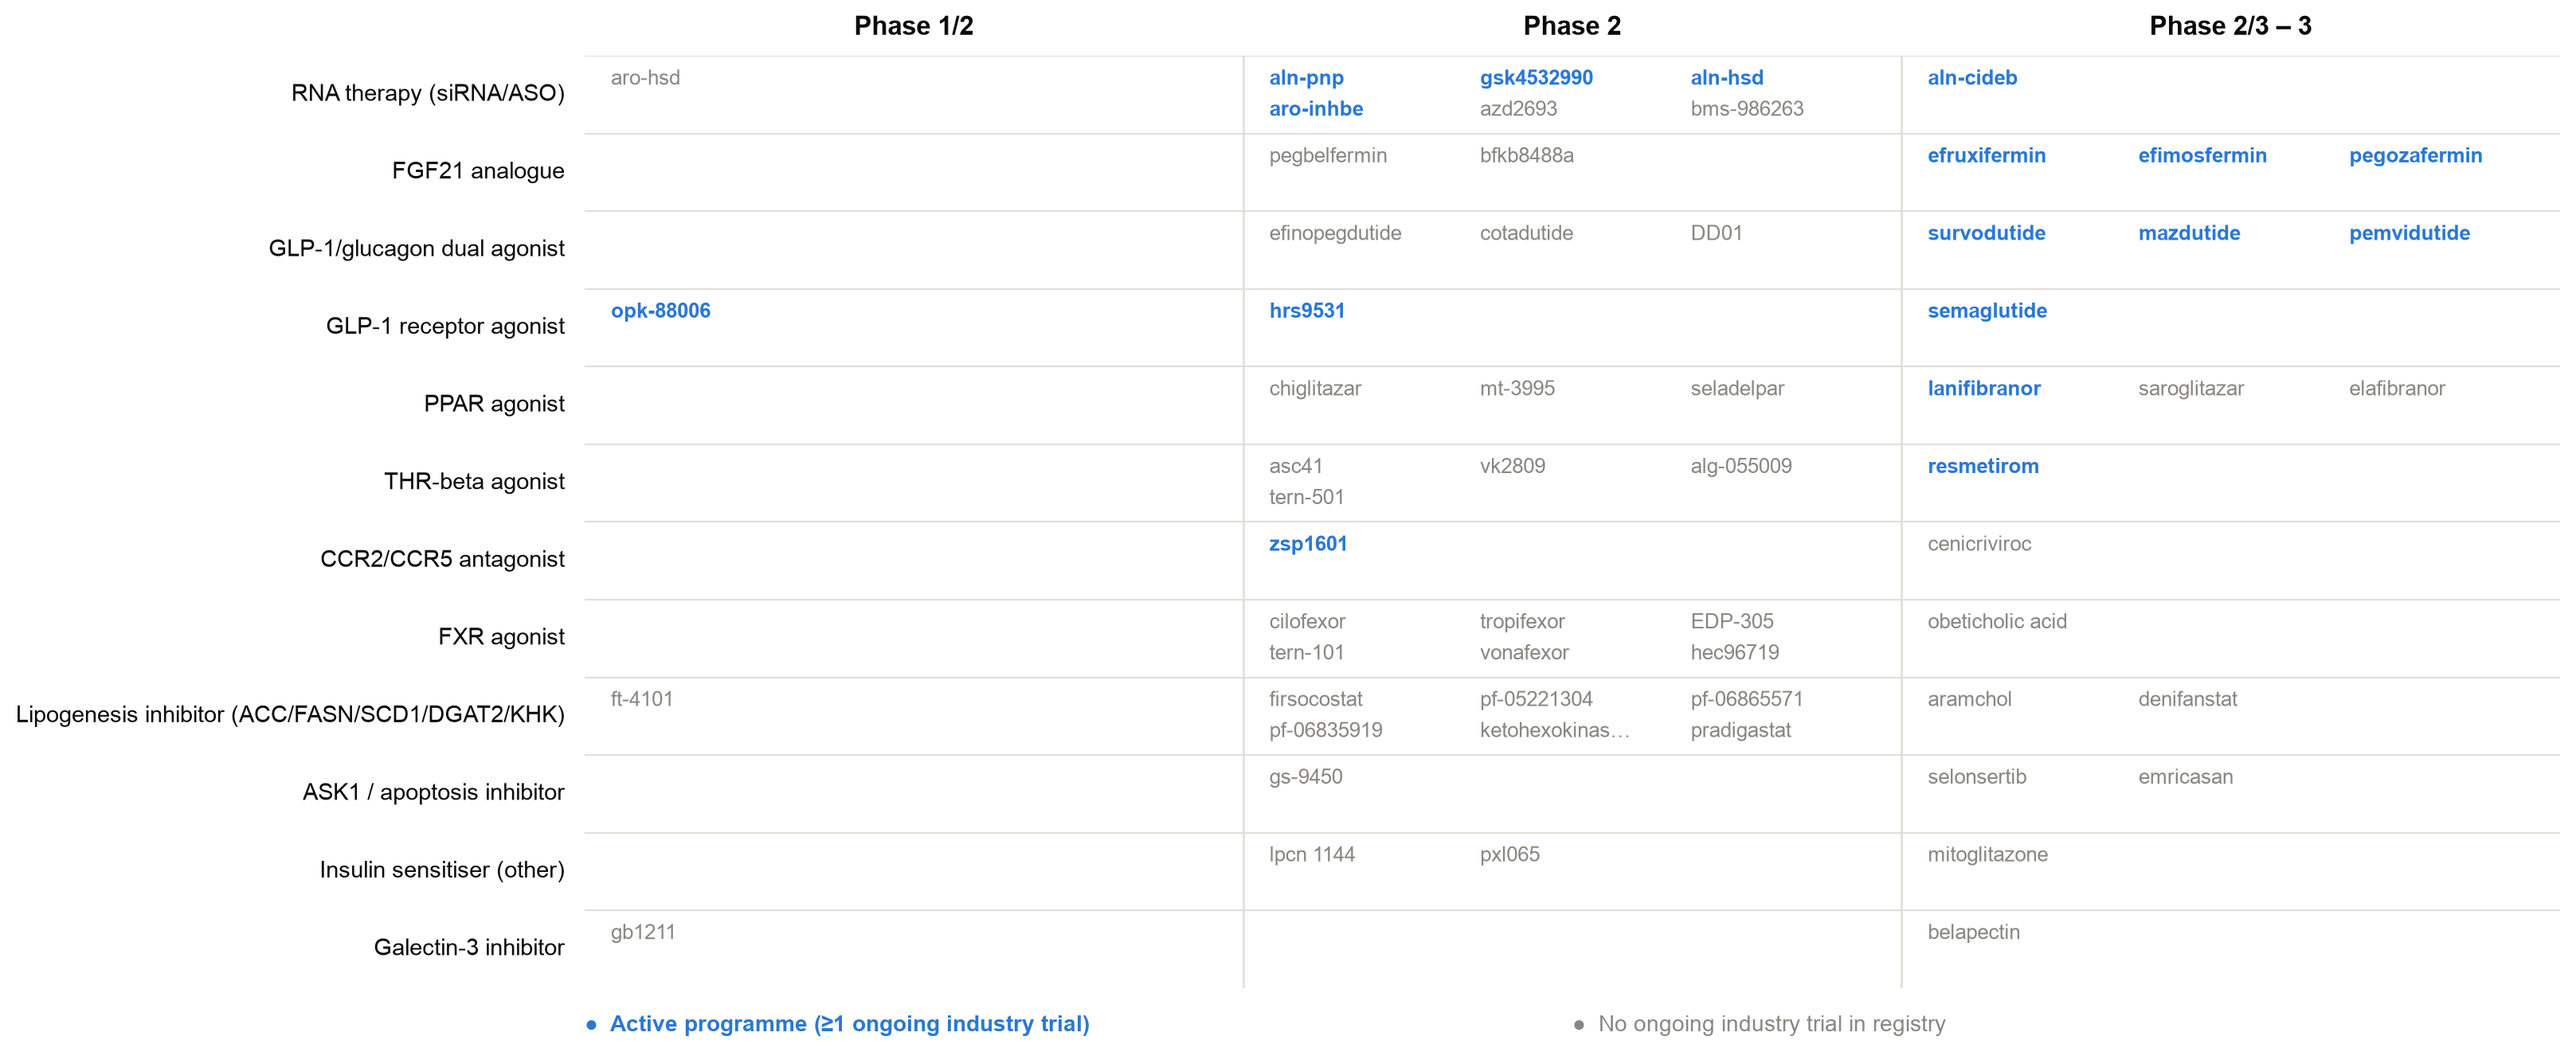

In [16]:
for name in ["pub_design", "pub_moa", "momentum"]:
    display(Image(filename=str(config.FIGURES_DIR / f"{name}.png"), width=650))
display(Image(filename=str(map_path), width=1000))

In [17]:
facts = analysis.compute_facts(pubmed_df, trials_df, extraction_df, drug_map,
                               landscape_df, compounds_df, qa, manual_accuracy)
display(pd.Series(facts, name="value").to_frame())
deck_path = deck.build(facts)

,value
run_date,12 Nov 2026
model,gpt-6-luna
cost,0.144236
n_articles,140
n_primary,95
n_meta,45
pub_positive,71%
n_trials_raw,498
n_relevant,585
n_raw_names,429


Deck saved -> outputs/findings_deck.pptx


## 5. Limitations

* **Sample, not census.** PubMed is a stratified sample of the top-relevance clinical articles (≈25 per year);
  ClinicalTrials.gov is complete for the query but registry status can lag reality.
* **Mechanism classes** for compounds whose source does not state a mechanism come from the model's
  pharmacology knowledge (flagged `moa_source = "model knowledge"`); compounds the model did not recognise
  are classed *Unknown* rather than guessed.
* **Efficacy direction** is a coarse label judged on the primary endpoint; it is not a substitute for reading
  the trial.
* **LLM accuracy** was checked with automated consistency tests and a 13-record manual audit (≈94% field
  accuracy); a larger audit would tighten that estimate.
* Regulatory context in the deck (FDA approvals of resmetirom, 2024, and semaglutide, 2025) is external
  knowledge, not pipeline output.